# P1-A8: Semantic Relationships and Retrieval

**QuadConnect · The Connectors · Team 13 · INFO 490, Fall 2026**

A retrieval-augmented generation (RAG) system that answers students' questions about QuadConnect from its student
handbook. It turns the handbook into chunks, embeds them, retrieves the chunks closest to a question, and lets a
language model answer from them:

**handbook → chunks → embeddings → vector store → top-k chunks → prompt → language model → answer**

| Part | What it does | Status |
|---|---|---|
| 1. Build the RAG pipeline | The knowledge base, three chunking strategies, three embedding models, retrieval and generation | In progress (Steps 1.1 to 1.3) |
| 2. System experiments | 3 embedding models × 3 chunking strategies = 9 configurations, tested on realistic questions | Next |
| 3. Failure analysis and improvement | Failures, their causes, and one fix shown before and after | Next |
| 4. System design reflection | Cost, RAG against its alternatives, and a design for 10,000 users a day | Next |

This notebook is independent of the Django app: it only uses QuadConnect's handbook, in `data/`.

**To run:** `pip install -r requirements.txt` in this folder, then *Run All*. The first run downloads the three
embedding models from Hugging Face (about 1.9 GB). The language model's replies are saved in
`results/generations.jsonl`, so a re-run reuses them and needs no API key. A new question needs `GROQ_API_KEY` in
`../.env` (never committed). Every path is relative to this folder.

In [1]:
# Setup: imports, paths and the settings every step uses. Run this cell first.
import os
import platform
import re
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*symlinks.*")  # Windows without Developer Mode copies files instead
warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars need ipywidgets; not needed here

from dotenv import load_dotenv

load_dotenv(Path("..") / ".env")  # before the Hugging Face libraries load: HF_TOKEN (optional) speeds up downloads

import pandas as pd
import sentence_transformers
import torch
from huggingface_hub.utils import disable_progress_bars
from huggingface_hub.utils import logging as hub_logging
from IPython.display import display
from transformers.utils import logging as hf_logging

disable_progress_bars()
hf_logging.disable_progress_bar()
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
DATA, RESULTS = Path("data"), Path("results")
RESULTS.mkdir(exist_ok=True)
GROQ_API_KEY = os.getenv("GROQ_API_KEY") or None  # needed only for a question whose answer is not saved yet

FIXED_WORDS = 120  # Step 1.2: the size of a fixed-length chunk, about one handbook paragraph
LONG_PARAGRAPH = 150  # Step 1.2: the hybrid strategy splits a paragraph longer than this
TOP_K = 3  # Step 1.4: chunks retrieved for each question
print(f"{platform.platform()} | {os.cpu_count()} logical CPUs | torch {torch.__version__} | "
      f"sentence-transformers {sentence_transformers.__version__}")
print(f"GROQ_API_KEY: {'set' if GROQ_API_KEY else 'not set (saved answers only)'}")


def require(condition, message):
    """Stop the notebook with the reason if a check fails."""
    if not condition:
        raise RuntimeError(message)

Windows-10-10.0.26300-SP0 | 16 logical CPUs | torch 2.14.1+cpu | sentence-transformers 6.2.0
GROQ_API_KEY: set


## Step 1.1: Define the knowledge base

**The dataset is QuadConnect's student handbook** (`data/handbook.md`): the help guide a student would read to
understand the app. It is the natural knowledge base for QuadConnect, because the questions students ask are about
how the app works: how matching decides, which times and places are possible, what happens to their feedback and
their data.

QuadConnect had no such document. Its database holds short fields (4 venues, 28 interests, 33 feedback notes), and
the repository's documents are written for developers. So we wrote the handbook for this assignment, from the app's
own code and pages. Every fact in it is one the app enforces or shows:

* the formats and preferences come from `connect/models.py`: Friend Connect (1-on-1) and Squad Connect (4 to 8
  students), the five-step social energy scale, weekends only in four two-hour windows, the 0–100 fit score and the
  check-in code;
* the venues, their seats and arrival notes, the interests and the colleges come from the seeded database;
* sign-in, cookies and data sharing come from the Privacy page and the settings, the venue check from
  `connect/ai_venues.py`, and search from the search pages.

**How the document is organised:** 13 sections, each about one subject, each made of paragraphs. A *paragraph* is a
block of text between blank lines under a `## ` section heading; headings are not paragraphs. Each paragraph covers
one idea, and the last section is a set of questions and answers, one question per paragraph. The table below checks
the brief's size requirements.

In [2]:
def read_handbook(path):
    """The handbook as paragraphs: one row per block of text between blank lines, under its section heading."""
    rows, section, number = [], None, 0
    for block in re.split(r"\n\s*\n", path.read_text(encoding="utf-8").strip()):
        block = " ".join(block.split())
        if block.startswith("## "):  # a section heading, such as "## 4. Setting your availability"
            section, number = block[3:], 0
            continue
        if block.startswith("# "):  # the document's title
            continue
        number += 1
        rows.append({"Paragraph": f"S{int(section.split('.')[0]):02d}-P{number}", "Section": section,
                     "Words": len(block.split()), "Text": block})
    return pd.DataFrame(rows)


handbook = read_handbook(DATA / "handbook.md")
words = handbook["Words"]
requirements = pd.DataFrame([
    ("Number of paragraphs", "at least 20; 30-50 recommended", f"{len(handbook)}", 30 <= len(handbook) <= 50),
    ("Paragraph length", "about 80-200 words each", f"{words.min()} to {words.max()} words (mean {words.mean():.0f})",
     words.between(80, 200).all()),
    ("Total size", "2,000-5,000 words", f"{words.sum():,} words", 2_000 <= words.sum() <= 5_000),
], columns=["Size requirement (brief, Step 1.2)", "The brief asks for", "The handbook has", "Met"])
display(requirements)
require(requirements["Met"].all(), "the knowledge base does not meet the brief's size requirements")

sections = handbook.groupby("Section", sort=False).agg(Paragraphs=("Paragraph", "count"), Words=("Words", "sum"))
display(sections)
print("One paragraph, as the pipeline sees it:\n")
print(handbook.loc[handbook["Paragraph"] == "S06-P2", ["Paragraph", "Section", "Words"]].to_string(index=False))
print(handbook.loc[handbook["Paragraph"] == "S06-P2", "Text"].iloc[0])

,"Size requirement (brief, Step 1.2)",The brief asks for,The handbook has,Met
0,Number of paragraphs,at least 20; 30-50 recommended,44,True
1,Paragraph length,about 80-200 words each,90 to 165 words (mean 111),True
2,Total size,"2,000-5,000 words","4,875 words",True


,Paragraphs,Words
Section,,
1. About QuadConnect,3,353
2. Creating an account and signing in,3,346
3. Building your profile,5,594
4. Setting your availability,2,222
5. How weekly matching works,4,473
"6. Meeting up: venues, check-in and icebreakers",4,504
7. Suggesting a new venue,4,466
8. Finding students,4,419
9. After the meetup: feedback,3,290


One paragraph, as the pipeline sees it:

Paragraph                                         Section  Words
   S06-P2 6. Meeting up: venues, check-in and icebreakers    165
Each venue page tells you how to find your group. It gives the street address, says whether the place is indoors or outdoors and how many people it seats, and adds an arrival note that says exactly where to wait. At the Illini Union you meet at the main entrance, in the ground floor lobby. At the Grainger Engineering Library you meet in the first floor commons. At the Main Quad, the only outdoor venue, you meet at the south end, by the Alma Mater statue. At Espresso Royale on Goodwin you meet in the counter seating area. The Illini Union seats twelve people, the Grainger Engineering Library eight, the Main Quad twenty and Espresso Royale six. A full squad of eight therefore fits every venue except Espresso Royale, which suits Friend Connect meetups and smaller squads. If you are not sure where to go, open the venue pa

## Step 1.2: Text representation and chunking

**Paragraphs** are defined in Step 1.1: a block of text between blank lines, under a section heading. A section is
about one subject, so **a section boundary is a topic boundary**, and no chunk may cross one.

**Sentences** end at `.`, `!` or `?` followed by a space and a capital letter, a digit or a quote. The handbook avoids
abbreviations with full stops (it says "for example", not "e.g."), so a sentence never ends early; the code below
checks that every sentence it finds starts with a capital and ends with punctuation.

**The three strategies.** None of them splits a sentence, and none puts two sections in one chunk:

| Strategy | How a chunk is made |
|---|---|
| 1. Fixed length | Whole sentences are packed, in order, into chunks of at most 120 words, about one paragraph's length. Paragraph boundaries are ignored, but each section starts a new chunk. A sentence that would push a chunk past the limit starts the next chunk instead of being cut. |
| 2. Overlapping paragraphs | Each chunk is two adjacent paragraphs of the same section: paragraphs 1 + 2, then 2 + 3, and so on. |
| 3. Hybrid (structure-aware) | One paragraph per chunk, because a handbook paragraph is one idea, with its section title in front so that the chunk names its topic. A paragraph over 150 words is split in two at the sentence boundary nearest its middle, and both halves keep the title. A question in the FAQ stays in the same chunk as its answer. |

**How the overlap is implemented:** a window two paragraphs wide slides through each section one paragraph at a time
(a stride of one). Neighbouring chunks therefore share a whole paragraph, half of each chunk, and every paragraph
except a section's first and last appears in two chunks. The window restarts at each section, so a pair never
mixes two topics; a section of a single paragraph would become one chunk on its own.

The checks after the code prove the rules on every chunk: each one is a run of whole sentences from the handbook,
each comes from one section, and together the chunks of every strategy contain every sentence of the handbook.

In [3]:
import matplotlib.pyplot as plt
import numpy as np

SENTENCE_END = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")


def sentences(text):
    return SENTENCE_END.split(text.strip())


handbook["Sentences"] = handbook["Text"].map(sentences)
odd = [s for group in handbook["Sentences"] for s in group
       if not re.match(r"[A-Z0-9\"'(]", s) or not re.search(r"[.!?][\"')]?$", s)]
require(not odd, f"the sentence splitter met something unexpected: {odd[:3]}")
print(f"{handbook['Sentences'].map(len).sum()} sentences in {len(handbook)} paragraphs, all split cleanly")


def make_chunk(strategy, number, section, paragraphs, body, heading=""):
    return {"Chunk": f"{strategy[:3].lower()}-{number:02d}", "Strategy": strategy, "Section": section,
            "Paragraphs": tuple(dict.fromkeys(paragraphs)), "Words": len(body.split()), "Heading": heading,
            "Body": body, "Text": f"{heading}\n{body}" if heading else body}


def fixed_length(book, max_words=FIXED_WORDS):
    """Whole sentences packed into chunks of at most max_words; each section starts a new chunk."""
    chunks = []
    for section, part in book.groupby("Section", sort=False):
        current, sources = [], []
        for row in part.itertuples():
            for sentence in row.Sentences:
                if current and len(" ".join(current + [sentence]).split()) > max_words:
                    chunks.append(make_chunk("Fixed", len(chunks) + 1, section, sources, " ".join(current)))
                    current, sources = [], []
                current.append(sentence)
                sources.append(row.Paragraph)
        chunks.append(make_chunk("Fixed", len(chunks) + 1, section, sources, " ".join(current)))
    return pd.DataFrame(chunks)


def overlapping(book):
    """Two adjacent paragraphs of the same section per chunk, with a stride of one paragraph."""
    chunks = []
    for section, part in book.groupby("Section", sort=False):
        rows = list(part.itertuples())
        pairs = list(zip(rows, rows[1:], strict=False)) or [(rows[0],)]  # a one-paragraph section stays one chunk
        for pair in pairs:
            chunks.append(make_chunk("Overlapping", len(chunks) + 1, section, [r.Paragraph for r in pair],
                                     "\n\n".join(r.Text for r in pair)))
    return pd.DataFrame(chunks)


def hybrid(book, long=LONG_PARAGRAPH):
    """One paragraph per chunk, titled with its section; a paragraph over `long` words is halved at a sentence."""
    chunks = []
    for row in book.itertuples():
        title = row.Section.split(". ", 1)[1]  # "4. Setting your availability" -> "Setting your availability"
        parts = [row.Sentences]
        if row.Words > long:
            running = np.cumsum([len(s.split()) for s in row.Sentences])
            cut = int(np.argmin(np.abs(running[:-1] - row.Words / 2))) + 1  # the boundary nearest the middle
            parts = [row.Sentences[:cut], row.Sentences[cut:]]
        for part in parts:
            chunks.append(make_chunk("Hybrid", len(chunks) + 1, row.Section, [row.Paragraph], " ".join(part),
                                     heading=f"{title}:"))
    return pd.DataFrame(chunks)


CHUNKS = {"Fixed": fixed_length(handbook), "Overlapping": overlapping(handbook), "Hybrid": hybrid(handbook)}

261 sentences in 44 paragraphs, all split cleanly


In [4]:
# The rules, checked on every chunk of every strategy.
all_sentences = [s for group in handbook["Sentences"] for s in group]
section_of = dict(zip(handbook["Paragraph"], handbook["Section"], strict=True))
checks = []
for name, table in CHUNKS.items():
    found = [s for body in table["Body"] for s in sentences(body)]
    whole = all(s in all_sentences for s in found)  # a cut sentence would not be in the handbook's list
    one_section = all(len({section_of[p] for p in ps}) == 1 for ps in table["Paragraphs"])
    complete = set(all_sentences) <= set(found)
    checks.append({"Strategy": name, "Chunks": len(table), "No sentence split": whole,
                   "No chunk crosses a section": one_section, "Every sentence covered": complete,
                   "Words per chunk (min-max)": f"{table['Words'].min()}-{table['Words'].max()}",
                   "Mean words": round(table["Words"].mean()),
                   "Paragraphs per chunk": round(table["Paragraphs"].map(len).mean(), 2),
                   "Chunks per paragraph": round(table["Paragraphs"].map(len).sum() / len(handbook), 2)})
checks = pd.DataFrame(checks).set_index("Strategy")
display(checks)
require(checks[["No sentence split", "No chunk crosses a section", "Every sentence covered"]].all().all(),
        "a chunk breaks a rule")

pairs = CHUNKS["Overlapping"]["Paragraphs"].tolist()
shared = [len(set(a) & set(b)) for a, b in zip(pairs, pairs[1:], strict=False) if section_of[a[0]] == section_of[b[0]]]
print(f"Overlap: neighbouring chunks in a section share {min(shared)} paragraph each ({len(shared)} pairs).")
split = CHUNKS["Hybrid"][CHUNKS["Hybrid"]["Paragraphs"].duplicated(keep=False)]
print(f"Hybrid: {split['Paragraphs'].nunique()} paragraphs over {LONG_PARAGRAPH} words were halved: "
      + ", ".join(sorted({p[0] for p in split['Paragraphs']})))
CHUNKS_ALL = pd.concat(CHUNKS.values(), ignore_index=True)
CHUNKS_ALL.assign(Paragraphs=CHUNKS_ALL["Paragraphs"].map(" ".join)).drop(columns="Body").to_csv(
    RESULTS / "chunks.csv", index=False, lineterminator="\n")
print(f"All {len(CHUNKS_ALL)} chunks saved to results/chunks.csv")

,Chunks,No sentence split,No chunk crosses a section,Every sentence covered,Words per chunk (min-max),Mean words,Paragraphs per chunk,Chunks per paragraph
Strategy,,,,,,,,
Fixed,50,True,True,True,21-120,98,1.46,1.66
Overlapping,31,True,True,True,186-285,222,2.00,1.41
Hybrid,48,True,True,True,67-122,102,1.00,1.09


Overlap: neighbouring chunks in a section share 1 paragraph each (18 pairs).
Hybrid: 4 paragraphs over 150 words were halved: S03-P5, S05-P3, S06-P2, S07-P4
All 129 chunks saved to results/chunks.csv


=== Fixed
[fix-15] paragraphs S04-P1, S04-P2 | 116 words
   QuadConnect meetups happen only on weekends, so your availability is a set of weekend time windows. You can mark Saturday, Sunday or both, and each day has four two-hour windows: 10 AM to 12 PM, 12 to 2 PM, 2 to 4 PM and 4 to 6 PM. That gives eight possible slots in a week, and you can mark as many of them as you like. Each slot can be marked only once, so marking Saturday from 2 to 4 PM twice is not possible. All the windows fall in the daytime, between 10 AM and 6 PM, so every QuadConnect meetup takes place during the day. Availability is the one hard rule in matching.
[fix-16] paragraphs S04-P2 | 106 words
   Two students can be matched only if they share at least one free slot, because a meetup needs a time that everyone can make. Interests and preferences decide how good a match is, but a shared slot decides whether a match is possible at all. That makes your availability the most important part of your profile to keep up

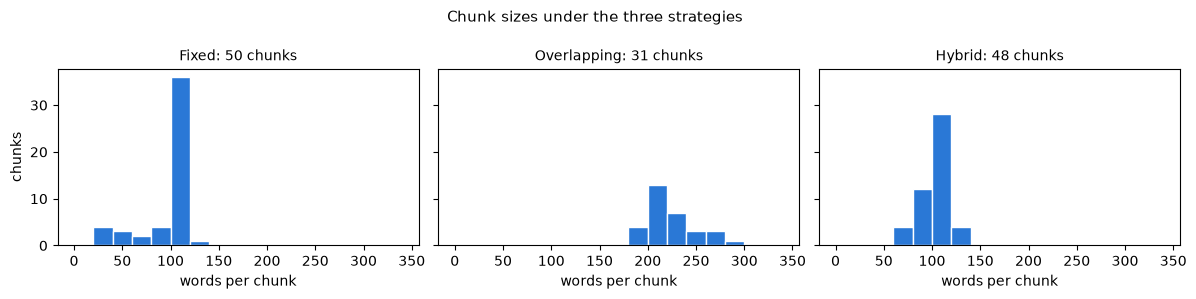

In [5]:
# One section under each strategy: Section 4, "Setting your availability" (two paragraphs).
for name, table in CHUNKS.items():
    print(f"=== {name}")
    for row in table[table["Section"].str.startswith("4.")].itertuples():
        print(f"[{row.Chunk}] paragraphs {', '.join(row.Paragraphs)} | {row.Words} words")
        print("   " + row.Text.replace("\n", "\n   ")[:600] + (" ..." if len(row.Text) > 600 else ""))
    print()

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (name, table) in zip(axes, CHUNKS.items(), strict=True):
    ax.hist(table["Words"], bins=range(0, 360, 20), color="#2a78d6", edgecolor="white")
    ax.set_title(f"{name}: {len(table)} chunks", fontsize=10)
    ax.set_xlabel("words per chunk")
axes[0].set_ylabel("chunks")
fig.suptitle("Chunk sizes under the three strategies", fontsize=11)
plt.tight_layout()
plt.show()

## Step 1.3: Embedding pipeline

**Three embedding models of different sizes**, all free on Hugging Face and loaded with `sentence-transformers`:

| Size | Model | Parameters | Dimensions |
|---|---|---|---|
| Small | `BAAI/bge-small-en-v1.5` | 33 million | 384 |
| Medium | `BAAI/bge-base-en-v1.5` | 109 million | 768 |
| Large | `BAAI/bge-large-en-v1.5` | 335 million | 1,024 |

We sort them by the length of the vectors they produce, the brief's categories (about 384, about 768, and 1,024 to
1,536). All three come from the same family, BAAI's BGE v1.5, trained the same way, so the main difference between
them is size. That keeps the comparison in Part 2 fair: a change in retrieval comes from the model's size, not from a
different training recipe.

**Embedding:** each chunk's text, title included, becomes one vector, scaled to length 1 so that the cosine
similarity of two vectors is simply their dot product. A question gets BGE's retrieval instruction in front, as its
model card recommends for short queries; the chunks do not.

**The searchable structure:** one `VectorStore` per model and strategy, nine in all. It holds a matrix with one row per
chunk and the chunk table beside it. A search multiplies the matrix by the question's vector and returns the
highest-scoring rows. The search is exact, and for a few hundred chunks it takes well under a millisecond; Part 4
covers what changes at scale.

**Checks:** no chunk is longer than the model's 512-token input, so nothing is cut off before it is embedded; and
every chunk, searched with its own vector, finds itself first.

In [6]:
import time

from sentence_transformers import SentenceTransformer

EMBEDDERS = {"Small": "BAAI/bge-small-en-v1.5", "Medium": "BAAI/bge-base-en-v1.5", "Large": "BAAI/bge-large-en-v1.5"}
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "  # BGE v1.5 model cards


class VectorStore:
    """One embedding model's vectors for one chunking strategy, searched by cosine similarity."""

    def __init__(self, embedder, chunks):
        self.embedder, self.chunks = embedder, chunks.reset_index(drop=True)
        started = time.perf_counter()
        self.vectors = embedder.encode(self.chunks["Text"].tolist(), batch_size=16, normalize_embeddings=True,
                                       convert_to_numpy=True).astype(np.float32)
        self.index_seconds = time.perf_counter() - started

    def embed_query(self, query):
        return self.embedder.encode(QUERY_INSTRUCTION + query, normalize_embeddings=True, convert_to_numpy=True)

    def search(self, query_vector, k=TOP_K):
        scores = self.vectors @ query_vector  # cosine similarity: every vector has length 1
        top = np.argsort(-scores)[:k]
        return self.chunks.iloc[top].assign(Rank=range(1, len(top) + 1), Score=scores[top].round(4))


MODELS, STORES, stats = {}, {}, []
for size, model_id in EMBEDDERS.items():
    started = time.perf_counter()
    MODELS[size] = SentenceTransformer(model_id, device="cpu")
    load_s = time.perf_counter() - started
    embedder = MODELS[size]
    for name, table in CHUNKS.items():
        STORES[size, name] = store = VectorStore(embedder, table)
        longest = max(len(embedder.tokenizer(text)["input_ids"]) for text in table["Text"])
        hits = [int(np.argmax(store.vectors @ store.vectors[i])) == i for i in range(len(table))]
        stats.append({"Size": size, "Model": model_id, "Parameters (M)": round(sum(p.numel() for p in
                      embedder.parameters()) / 1e6), "Dimensions": store.vectors.shape[1], "Strategy": name,
                      "Chunks": len(table), "Longest chunk (tokens)": longest, "Model limit": embedder.max_seq_length,
                      "Load (s)": round(load_s, 1), "Index (s)": round(store.index_seconds, 2),
                      "ms per chunk": round(store.index_seconds / len(table) * 1000, 1),
                      "Vectors (KB)": round(store.vectors.nbytes / 1024, 1),
                      "Finds itself first": f"{sum(hits)}/{len(hits)}"})
EMBEDDING_STATS = pd.DataFrame(stats)
display(EMBEDDING_STATS)
require((EMBEDDING_STATS["Longest chunk (tokens)"] <= EMBEDDING_STATS["Model limit"]).all(),
        "a chunk would be cut off")
require(all(s.split("/")[0] == s.split("/")[1] for s in EMBEDDING_STATS["Finds itself first"]),
        "a chunk does not find itself first")
EMBEDDING_STATS.to_csv(RESULTS / "embedding_stats.csv", index=False, lineterminator="\n")
print(f"{len(STORES)} vector stores: 3 models x 3 strategies. Saved to results/embedding_stats.csv")

,Size,Model,Parameters (M),Dimensions,Strategy,Chunks,Longest chunk (tokens),Model limit,Load (s),Index (s),ms per chunk,Vectors (KB),Finds itself first
0,Small,BAAI/bge-small-en-v1.5,33,384,Fixed,50,156,512,0.8,1.60,32.0,75.0,50/50
1,Small,BAAI/bge-small-en-v1.5,33,384,Overlapping,31,346,512,0.8,2.27,73.1,46.5,31/31
2,Small,BAAI/bge-small-en-v1.5,33,384,Hybrid,48,162,512,0.8,1.72,35.8,72.0,48/48
3,Medium,BAAI/bge-base-en-v1.5,109,768,Fixed,50,156,512,0.9,5.03,100.6,150.0,50/50
4,Medium,BAAI/bge-base-en-v1.5,109,768,Overlapping,31,346,512,0.9,7.00,225.7,93.0,31/31
5,Medium,BAAI/bge-base-en-v1.5,109,768,Hybrid,48,162,512,0.9,5.04,105.1,144.0,48/48
6,Large,BAAI/bge-large-en-v1.5,335,1024,Fixed,50,156,512,2.1,17.04,340.8,200.0,50/50
7,Large,BAAI/bge-large-en-v1.5,335,1024,Overlapping,31,346,512,2.1,23.96,772.9,124.0,31/31
8,Large,BAAI/bge-large-en-v1.5,335,1024,Hybrid,48,162,512,2.1,17.50,364.7,192.0,48/48


9 vector stores: 3 models x 3 strategies. Saved to results/embedding_stats.csv
